# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

import csv
from aitlas.datasets import LarchCasebearerTreeDamageDataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects with bounding boxes

Total number of patches: 1533


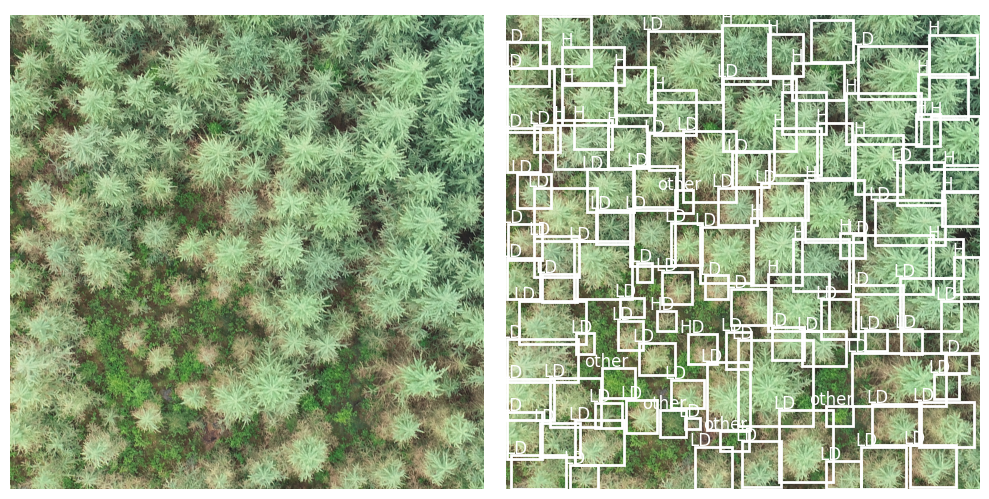

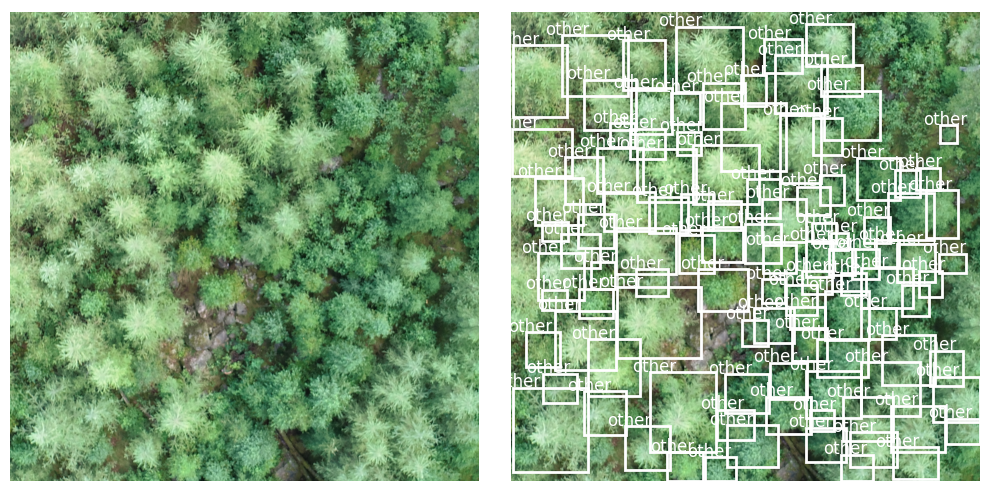

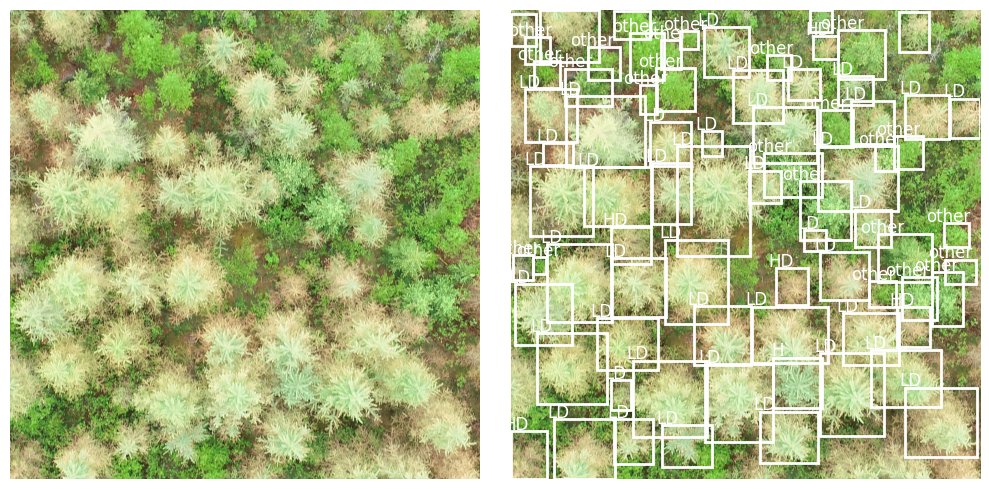

In [7]:
dataset_config = {
    "image_dir": "/home/dragik/data/FAIR_EO/larch_casebearer/images/",
    "annotations_dir": "/home/dragik/data/FAIR_EO/larch_casebearer/annotations/",
}
dataset = LarchCasebearerTreeDamageDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(1);
dataset.show_image(30);
dataset.show_image(90);

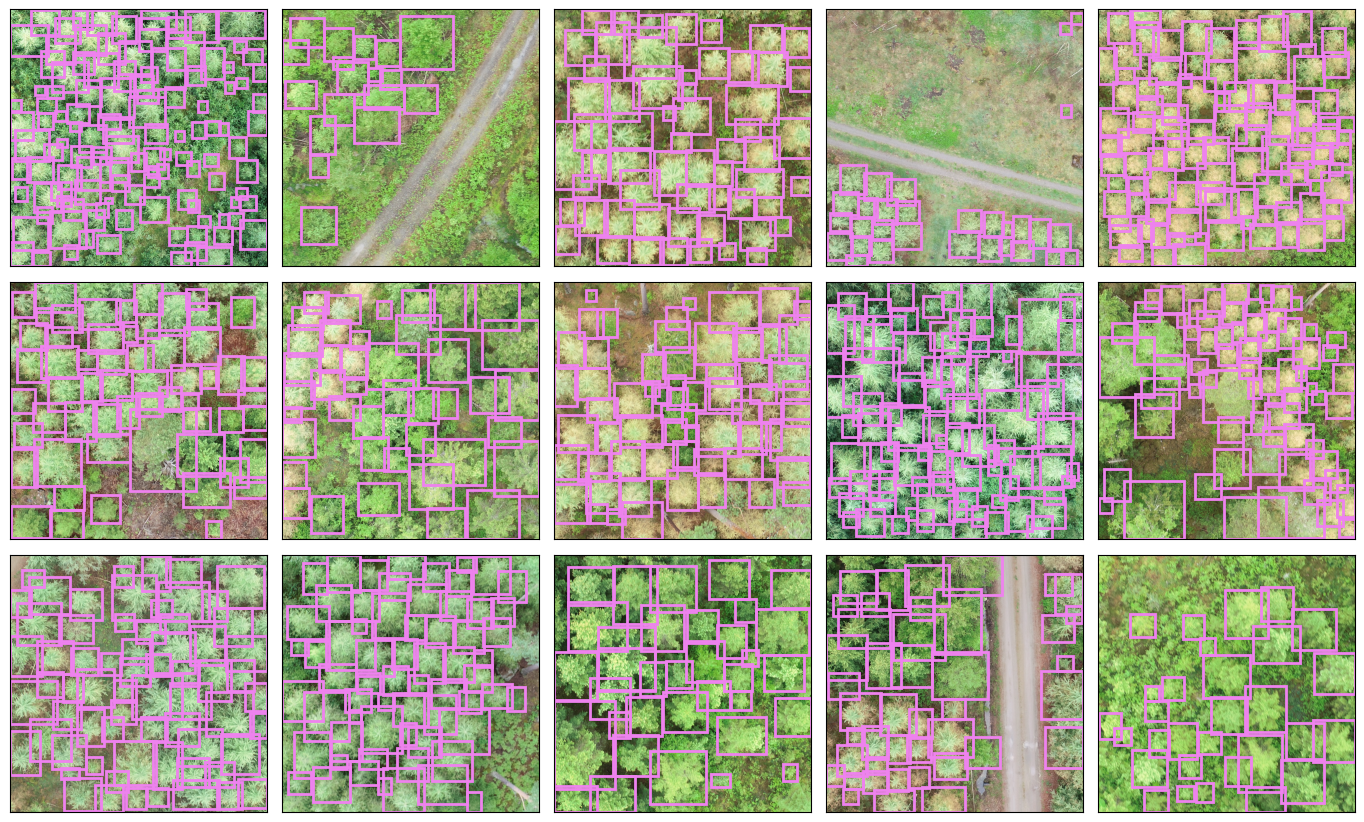

In [8]:
dataset.show_batch(15);

In [9]:
dataset.data_distribution_table()

,Label,Count
0,other,56812
1,LD,33297
2,HD,9084
3,H,2638


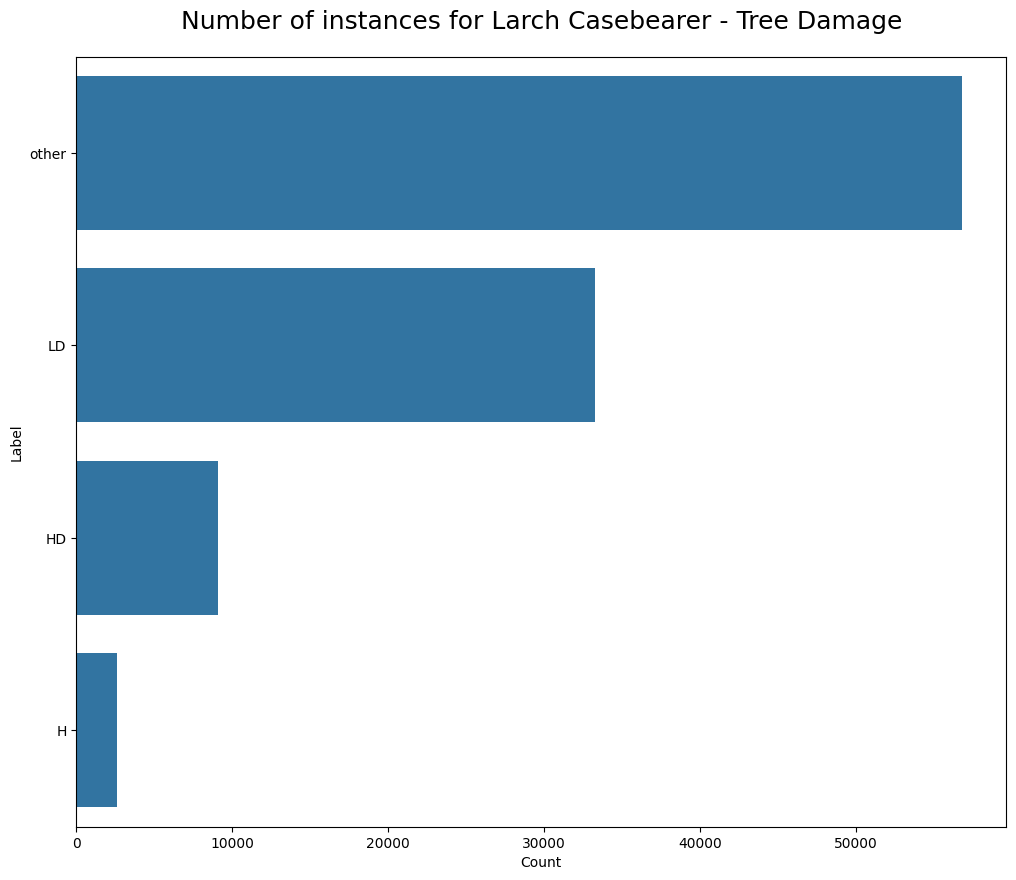

In [10]:
dataset.data_distribution_barchart();

## Load train data

In [5]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "image_dir": "/home/dragik/data/FAIR_EO/larch_casebearer/images/",
    "annotations_dir": "/home/dragik/data/FAIR_EO/larch_casebearer/annotations/",
    "imageset_file": "/home/dragik/data/FAIR_EO/larch_casebearer/larch_casebearer_train.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = LarchCasebearerTreeDamageDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 1228


## Create the model

In [6]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/larch_casebearer/experiments/tree_damage/"
model_config = {
    "num_classes": 5, #include the background class
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-09-15 12:15:42,974 INFO Starting training.
training: 100%|██████████| 154/154 [00:53<00:00,  2.89it/s]
2025-09-15 12:16:36,688 INFO epoch: 1, time: 53, loss:  1.12007
testing on train set: 100%|██████████| 154/154 [00:40<00:00,  3.84it/s]
2025-09-15 12:19:16,372 INFO map:0.2719208002090454, map_50:0.4707695543766022, map_75:0.2915915846824646, map_small:0.16112419962882996, map_medium:0.29221412539482117, map_large:0.3759489953517914, mar_1:0.014664669521152973, mar_10:0.10000978410243988, mar_100:0.3335452079772949, mar_small:0.24347877502441406, mar_medium:0.3499791622161865, mar_large:0.44953611493110657, map_per_class:tensor(0.), tensor(0.1205), tensor(0.4965), tensor(0.4706), mar_100_per_class:tensor(0.), tensor(0.1728), tensor(0.6025), tensor(0.5588), classes:tensor(1, dtype=torch.int32), tensor(2, dtype=torch.int32), tensor(3, dtype=torch.int32), tensor(4, dtype=torch.int32)
training: 100%|██████████| 154/154 [00:52<00:00,  2.91it/s]
2025-09-15 12:20:09,357 INFO epoch: 2, t

## Evaluate the model

In [8]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "image_dir": "/home/dragik/data/FAIR_EO/larch_casebearer/images/",
    "annotations_dir": "/home/dragik/data/FAIR_EO/larch_casebearer/annotations/",
    "imageset_file": "/home/dragik/data/FAIR_EO/larch_casebearer/larch_casebearer_val.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = LarchCasebearerTreeDamageDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/larch_casebearer/experiments/tree_damage/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 153


2025-09-15 13:05:14,610 INFO Loading checkpoint /home/dragik/data/FAIR_EO/larch_casebearer/experiments/tree_damage/checkpoint.pth.tar
2025-09-15 13:05:15,002 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/larch_casebearer/experiments/tree_damage/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 20/20 [00:05<00:00,  3.45it/s]


[{'map': 0.37190940976142883,
  'map_50': 0.6035794019699097,
  'map_75': 0.4192740023136139,
  'map_small': 0.1928679198026657,
  'map_medium': 0.42138829827308655,
  'map_large': 0.5582669973373413,
  'mar_1': 0.02680523879826069,
  'mar_10': 0.17645230889320374,
  'mar_100': 0.4753279983997345,
  'mar_small': 0.2737852931022644,
  'mar_medium': 0.5300962328910828,
  'mar_large': 0.679291844367981,
  'map_per_class': [tensor(0.2446),
   tensor(0.2499),
   tensor(0.4768),
   tensor(0.5163)],
  'mar_100_per_class': [tensor(0.4099),
   tensor(0.3507),
   tensor(0.5566),
   tensor(0.5841)],
  'classes': [tensor(1, dtype=torch.int32),
   tensor(2, dtype=torch.int32),
   tensor(3, dtype=torch.int32),
   tensor(4, dtype=torch.int32)]}]

## Predictions

2025-09-15 13:06:16,999 INFO Loading checkpoint /home/dragik/data/FAIR_EO/larch_casebearer/experiments/tree_damage/checkpoint.pth.tar
2025-09-15 13:06:17,386 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/larch_casebearer/experiments/tree_damage/checkpoint.pth.tar at epoch 11


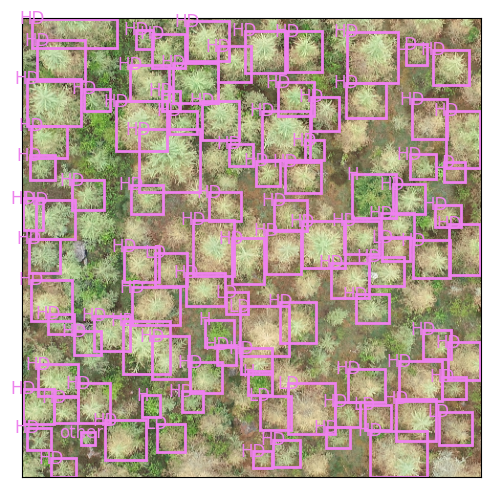

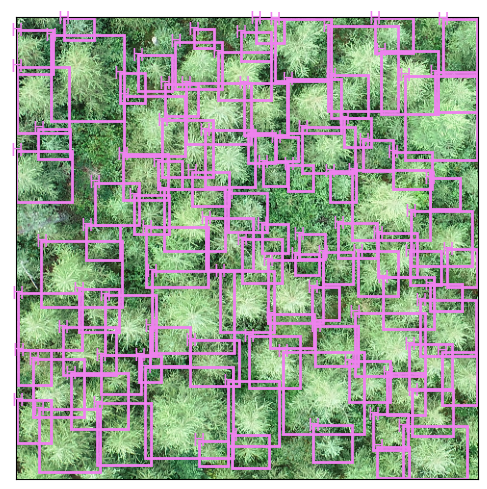

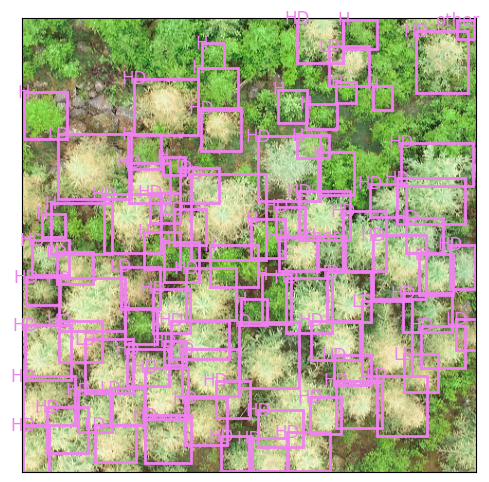

In [10]:
model_config = {
    "num_classes": 5,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "/home/dragik/data/FAIR_EO/larch_casebearer/experiments/tree_damage/checkpoint.pth.tar"
labels = ['no-data','other','LD','HD','H']
transform = Resize()
model.load_model(model_path)

csv_file = "/home/dragik/data/FAIR_EO/larch_casebearer/larch_casebearer_test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('/home/dragik/data/FAIR_EO/larch_casebearer/' + test_list[0])
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/larch_casebearer/' + test_list[10])
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/larch_casebearer/' + test_list[20])
fig = model.detect_objects(image, labels, transform)